# Graph Neural Networks from Scratch — Tutorial 4: PyTorch Geometric and the Cora Dataset

### From implementing GCNs to learning with real-world graph data

*📺 Video on YouTube | 🐍 Python · PyTorch · PyTorch Geometric | Beginner–Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorial 2, we implemented a **Graph Convolutional Network (GCN) forward pass from scratch using NumPy**. We explored self-loops, degree matrices, graph normalization, and neighbourhood aggregation to understand how information flows through a graph.

In Tutorial 3, we introduced **PyTorch** and transformed our GCN into a trainable neural network. We explored learnable parameters, automatic differentiation, backpropagation, and the complete training process for node classification.

Now that we understand both the mathematics behind graph convolution and how to train a GCN, it is time to move beyond manually constructed graphs and work with a real-world graph dataset.

In this tutorial, we will introduce **PyTorch Geometric (PyG)**, a library built on PyTorch for developing graph neural networks. We will use the **Cora citation network** to build a complete node-classification workflow and understand how PyG represents graph data and implements graph convolution.

Our focus is not simply to use a library. We want to understand how its components connect to the mathematical concepts and implementations we have already developed.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| **4** | **PyTorch Geometric and the Cora Dataset** | **PyG, real-world graph data, practical GCN implementation** | **📍 You are here** |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | Planned |
| 6 | Graph Attention Networks (GAT) | attention-based neighbourhood aggregation | Planned |
| 7 | GraphSAGE and Advanced Aggregation | scalable neighbourhood learning | Planned |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems.

---

In this tutorial, we will explore the essential components of practical GNN development using PyTorch Geometric:

- Graph representation using `edge_index`.
- Understanding PyG's `Data` object.
- Loading and exploring the Cora citation-network dataset.
- Node features, graph connectivity, and node labels.
- Training, validation, and test masks.
- Implementing graph convolution using `GCNConv`.
- Building and training a GCN with PyTorch Geometric.
- Evaluating node-classification performance.
- Connecting PyG's implementation to the GCN mathematics from Tutorial 2.

We will begin by understanding how PyG stores graph data. Then, we will load Cora, build a GCN, and train it to classify scientific publications.

## The learning process

Our practical GCN workflow will follow this sequence:

```text
          Cora Dataset
                |
                v
       Graph Representation
         (Data + edge_index)
                |
                v
       Node Features + Labels
                |
                v
             GCNConv
                |
                v
          Model Predictions
                |
                v
          Calculate Loss
                |
                v
         Backpropagation
                |
                v
          Update Weights
                |
                v
       Evaluate Model Performance
```

Unlike our earlier tutorials, where we manually constructed graph representations and implemented the convolution operation ourselves, PyG provides specialised data structures and graph convolution layers.

However, the underlying mathematics remains the same. We will examine how `GCNConv` relates to the normalized adjacency matrix and propagation equation we derived in Tutorial 2.

> **New to PyTorch Geometric?** Don't worry if you haven't used PyG before. We will introduce its graph representation and essential components step by step. Familiarity with Python, PyTorch, and the GCN concepts from the previous tutorials will be helpful.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay attention to how graph connectivity is represented independently of the node features. This separation is particularly useful when working with unstructured computational meshes, where cells or vertices are connected through mesh topology.

**Let's now move from implementing GCNs manually to building practical graph neural networks with PyTorch Geometric.**

## 1. Why PyTorch Geometric?

A dense adjacency matrix for \(N\) nodes has \(N^2\) entries. Real graphs are usually sparse: most pairs of nodes are not connected. Storing only the edges is more efficient.

PyG uses a compact representation called `edge_index`. It stores the source and destination node for each directed edge.

## 2. Installation

In terminal or notebook environment:

```bash
pip install torch-geometric
```

For many recent PyTorch versions this is sufficient. If your environment requires version-specific dependencies, consult the official PyG installation instructions.


In [3]:
import torch

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
    print("PyG:", torch_geometric.__version__)
except ImportError:
    print("PyTorch Geometric is not installed. Run: !pip install torch-geometric")


PyTorch: 2.11.0+cu130


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG: 2.8.1


In [2]:
#!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 24.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [torch-geometric] [torch-geometric]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


# Part I — Graph representation with `edge_index`

## 3. From adjacency matrix to edge list

Consider this undirected graph:

```text
      1
     / 
    /   
   0 ------ 2
```

Its adjacency matrix is:

$$
A=\begin{bmatrix}0&1&1\\1&0&0\\1&0&0\end{bmatrix}
$$

The non-zero entries correspond to four directed edges:

```text
0 → 1
0 → 2
1 → 0
2 → 0
```

PyG stores these in a tensor of shape $2\times E$:
- first row: source nodes
- second row: destination nodes
- each column: one directed edge

This resembles the coordinate (COO) representation used for sparse matrices.


In [5]:
import torch

edge_index = torch.tensor([
    [0, 0, 1, 2],  # source nodes
    [1, 2, 0, 0]   # destination nodes
], dtype=torch.long)

print(edge_index)
print("Shape:", edge_index.shape)

for source, target in edge_index.t().tolist():
    print(f"{source} -> {target}")


tensor([[0, 0, 1, 2],
        [1, 2, 0, 0]])
Shape: torch.Size([2, 4])
0 -> 1
0 -> 2
1 -> 0
2 -> 0


### Why two directions for an undirected edge?

An undirected connection between nodes 0 and 1 is normally represented as both `0 → 1` and `1 → 0`. This allows information to flow in both directions during message passing.

## 🧪 Hands-on Exercise 1

Create `edge_index` for this graph:

```text
0 ----- 1
|       |
|       |
2 ----- 3
```

Connections: 0–1, 0–2, 1–3, and 2–3. Include both directions, so the tensor should have shape `[2, 8]`.


In [ ]:
# TODO: create edge_index for the four-node graph.
# Include both directions for each undirected connection.

# edge_index = torch.tensor([...], dtype=torch.long)
# print(edge_index)
# print(edge_index.shape)


## 4. The PyG `Data` object

A graph may contain node features `x`, connectivity `edge_index`, labels `y`, masks, edge attributes, and graph-level attributes. PyG groups these tensors in a `Data` object.


In [7]:
from torch_geometric.data import Data

x = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0]
])
y = torch.tensor([0, 1, 0])

small_graph = Data(x=x, edge_index=edge_index, y=y) # using edge_index from the previous cell

print(small_graph)
print("Nodes:", small_graph.num_nodes)
print("Edges:", small_graph.num_edges)
print("Features per node:", small_graph.num_node_features)
print("x shape:", small_graph.x.shape)


Data(x=[3, 2], edge_index=[2, 4], y=[3])
Nodes: 3
Edges: 4
Features per node: 2
x shape: torch.Size([3, 2])


Conceptually, our graph \(G=(V,E,X,Y)\) is now represented by a Python object containing the corresponding tensors.

# Part II — The Cora citation network

## 5. What is Cora?

Cora is a standard benchmark for node classification:
- **Node:** a scientific paper
- **Edge:** a citation relationship
- **Node features:** a sparse representation of paper content
- **Node label:** the paper's research-topic category

Our task is to predict the topic of a paper using its features and its position in the citation graph. This is **node classification**, not graph classification.


## 6. Load and inspect Cora

PyG provides the Planetoid dataset collection, which includes Cora.


In [8]:
from torch_geometric.datasets import Planetoid

dataset = Planetoid(root="data/Planetoid", name="Cora")
data = dataset[0]

print(dataset)
print("Number of graphs:", len(dataset))
print("Nodes:", data.num_nodes)
print("Edges (directed entries):", data.num_edges)
print("Node features:", data.num_node_features)
print("Classes:", dataset.num_classes)

print("\nx shape:", data.x.shape)
print("edge_index shape:", data.edge_index.shape)
print("y shape:", data.y.shape)
print("First five labels:", data.y[:5])


Cora()
Number of graphs: 1
Nodes: 2708
Edges (directed entries): 10556
Node features: 1433
Classes: 7

x shape: torch.Size([2708, 1433])
edge_index shape: torch.Size([2, 10556])
y shape: torch.Size([2708])
First five labels: tensor([3, 4, 4, 0, 3])


Processing...
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/

The feature matrix has shape:

$$
X\in\mathbb{R}^{N\times F}
$$

where $N$ is the number of nodes and $F$ the number of features. The edge list has shape $2\times E$, and the label vector contains one class per node.

Cora's features are sparse. Graph sparsity and feature sparsity are different:
- **Graph sparsity:** only some pairs of nodes are connected.
- **Feature sparsity:** many feature entries are zero.


In [9]:
nonzero = (data.x != 0).sum().item()
total = data.x.numel()

print("Non-zero feature entries:", nonzero)
print("Total feature entries:", total)
print("Fraction non-zero:", nonzero / total)


Non-zero feature entries: 49216
Total feature entries: 3880564
Fraction non-zero: 0.012682692515830173


# Part III — Train, validation, and test masks

## 7. Semi-supervised node classification

Cora provides Boolean masks:

```python
data.train_mask
data.val_mask
data.test_mask
```

A `True` value means that node belongs to the corresponding split. The graph and features are available, but only training labels contribute to the optimization loss. This is a common **transductive** node-classification setup.


In [10]:
print("Training nodes:", int(data.train_mask.sum()))
print("Validation nodes:", int(data.val_mask.sum()))
print("Test nodes:", int(data.test_mask.sum()))
print("Mask shape:", data.train_mask.shape)


Training nodes: 140
Validation nodes: 500
Test nodes: 1000
Mask shape: torch.Size([2708])


The training objective is:

$$
\mathcal L_{\mathrm{train}}
=
CE\left(Z[\mathrm{train}],Y[\mathrm{train}]\right)
$$

Validation nodes help monitor generalization and make model choices. The test set should be reserved for final evaluation.

## 🧪 Hands-on Exercise 2

Calculate the fraction of nodes in each split. Do the three fractions add up to one?


In [11]:
N = data.num_nodes

for name, mask in [
    ("Train", data.train_mask),
    ("Validation", data.val_mask),
    ("Test", data.test_mask)
]:
    print(f"{name}: {mask.sum().item() / N:.3f}")


Train: 0.052
Validation: 0.185
Test: 0.369


# Part IV — Build a GCN with PyG

## 8. Connect `GCNConv` to the GCN equation

From Tutorial 2:

$$
H^{(l+1)}
=
\sigma\left(
\hat D^{-1/2}\hat A\hat D^{-1/2}H^{(l)}W^{(l)}
\right)
$$

PyG provides `GCNConv`, which implements this type of graph convolution using sparse connectivity.

Our two-layer model is:

$$
H^{(1)}=\operatorname{ReLU}(\operatorname{GCNConv}_1(X))
$$

$$
Z=\operatorname{GCNConv}_2(H^{(1)})
$$

The output $Z$ contains one vector of class logits per node.


In [12]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class GCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.0):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, output_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x


The first layer maps the input feature dimension \(F\) to hidden dimension \(H\). The second maps \(H\) to the number of classes \(C\).

In Tutorial 3, we manually implemented graph propagation. Here `GCNConv` handles the graph convolution internally.

## 9. Create the model and run a forward pass


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = data.to(device)

model = GCN(
    input_dim=dataset.num_node_features,
    hidden_dim=16,
    output_dim=dataset.num_classes
).to(device)

print(model)
print("Device:", device)


GCN(
  (conv1): GCNConv(1433, 16)
  (conv2): GCNConv(16, 7)
)
Device: cpu


In [14]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

print("Logits shape:", logits.shape)
print("Expected:", (data.num_nodes, dataset.num_classes))
print("Predicted classes for first 10 nodes:", logits.argmax(dim=1)[:10])


Logits shape: torch.Size([2708, 7])
Expected: (2708, 7)
Predicted classes for first 10 nodes: tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


For node $i$, the model returns $C$ scores:

$$
Z_i=[z_{i,1},z_{i,2},\ldots,z_{i,C}]
$$

The predicted class is $\hat y_i=\arg\max_c Z_{i,c}$. These scores are called **logits**. `CrossEntropyLoss` expects logits directly; do not apply softmax before passing them to the loss function.

# Part V — Train the GCN

## 10. One training step

We use Adam and cross-entropy. The loss is calculated only on nodes selected by `train_mask`.


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

model.train()
optimizer.zero_grad()

logits = model(data.x, data.edge_index)
loss = criterion(
    logits[data.train_mask],
    data.y[data.train_mask]
)

loss.backward()
optimizer.step()

print("One-step training loss:", loss.item())


One-step training loss: 1.946054458618164


The sequence is the same as ordinary PyTorch training:

```text
Forward pass → loss → backward pass → optimizer update
```

The graph-specific part is that each convolution receives both node features and `edge_index`.

## 11. Evaluation function


In [16]:
@torch.no_grad()
def accuracy(model, data, mask):
    model.eval()
    logits = model(data.x, data.edge_index)
    predictions = logits.argmax(dim=1)
    correct = (predictions[mask] == data.y[mask]).sum()
    return (correct.float() / mask.sum()).item()

print("Train accuracy:", accuracy(model, data, data.train_mask))
print("Validation accuracy:", accuracy(model, data, data.val_mask))


Train accuracy: 0.44285714626312256
Validation accuracy: 0.25


## 12. Full training loop

We start with a fresh model and track training loss, training accuracy, and validation accuracy.


In [17]:
model = GCN(
    input_dim=dataset.num_node_features,
    hidden_dim=16,
    output_dim=dataset.num_classes,
    dropout=0.0
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

history = {"loss": [], "train_acc": [], "val_acc": []}
epochs = 200

for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()

    logits = model(data.x, data.edge_index)
    loss = criterion(logits[data.train_mask], data.y[data.train_mask])

    loss.backward()
    optimizer.step()

    train_acc = accuracy(model, data, data.train_mask)
    val_acc = accuracy(model, data, data.val_mask)

    history["loss"].append(loss.item())
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:03d} | Loss {loss.item():.4f} | "
            f"Train {train_acc:.4f} | Val {val_acc:.4f}"
        )


Epoch 001 | Loss 1.9544 | Train 0.4214 | Val 0.2360
Epoch 020 | Loss 0.1721 | Train 1.0000 | Val 0.7640
Epoch 040 | Loss 0.0190 | Train 1.0000 | Val 0.7660
Epoch 060 | Loss 0.0164 | Train 1.0000 | Val 0.7700
Epoch 080 | Loss 0.0189 | Train 1.0000 | Val 0.7760
Epoch 100 | Loss 0.0173 | Train 1.0000 | Val 0.7780
Epoch 120 | Loss 0.0151 | Train 1.0000 | Val 0.7820
Epoch 140 | Loss 0.0137 | Train 1.0000 | Val 0.7820
Epoch 160 | Loss 0.0125 | Train 1.0000 | Val 0.7780
Epoch 180 | Loss 0.0116 | Train 1.0000 | Val 0.7780
Epoch 200 | Loss 0.0109 | Train 1.0000 | Val 0.7780


## 13. Plot the learning curves

Training loss tells us whether the model is fitting training labels. Comparing training and validation accuracy helps us spot possible overfitting.


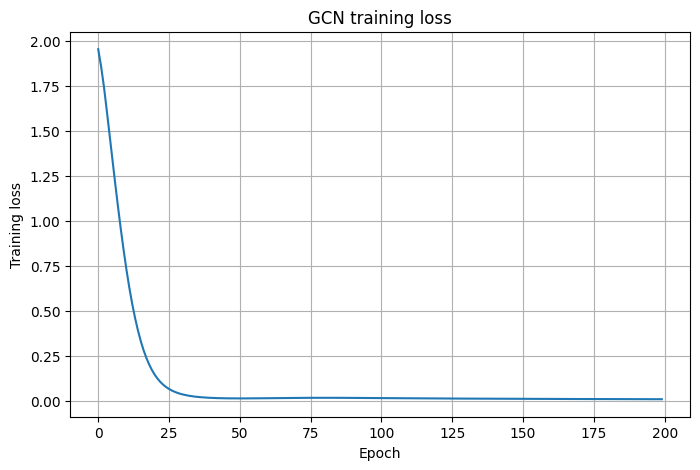

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("GCN training loss")
plt.grid(True)
plt.show()


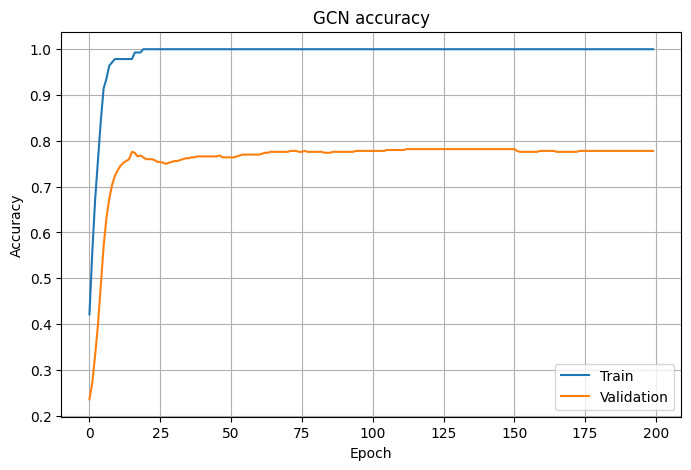

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GCN accuracy")
plt.legend()
plt.grid(True)
plt.show()


If training accuracy keeps improving while validation accuracy stops improving or declines, the model may be overfitting. Exact curves and scores vary with random initialization and software versions.

# Part VI — Final test evaluation

## 14. Evaluate on the test nodes

Use the test split for final evaluation, not for repeatedly tuning the model.


In [20]:
test_acc = accuracy(model, data, data.test_mask)
print(f"Test accuracy: {test_acc:.4f}")


Test accuracy: 0.8140


We now have a complete node-classification pipeline:

$$
\text{Graph}\rightarrow\text{GCN}\rightarrow\text{Logits}
\rightarrow\text{Masked loss}\rightarrow\text{Backpropagation}
\rightarrow\text{Predictions}
$$

The objective is to understand the workflow and data representation, not to chase one particular benchmark score.

# Part VII — What happens inside a graph convolution?

## 15. Connect PyG to our earlier implementation

In Tutorial 2, we:
1. Added self-loops: $\hat A=A+I$
2. Calculated degrees: $\hat D$
3. Normalized adjacency: $S=\hat D^{-1/2}\hat A\hat D^{-1/2}$
4. Propagated features: $H'=\sigma(SHW)$

In Tutorial 4, we call:

```python
x = self.conv1(x, edge_index)
```

`GCNConv` performs the corresponding normalized graph convolution using sparse graph connectivity. The implementation is optimized, but the underlying idea is the one we already derived.


## 16. The message-passing viewpoint

A graph convolution can also be described as message passing:

1. Each node receives information from its neighbors.
2. Neighbor information is weighted and aggregated.
3. The node representation is transformed.
4. The updated representation can be passed to the next layer.

A simplified expression is:

$$
h_i^{(l+1)}
=
\sigma\left(
\sum_{j\in\mathcal N(i)}
\alpha_{ij}h_j^{(l)}W^{(l)}
\right)
$$

This viewpoint generalizes beyond GCNs. It will help us understand GraphSAGE, Graph Attention Networks, and custom message-passing layers.


# Part VIII — Inspect predictions

## 17. Compare predicted and true labels


In [21]:
model.eval()
with torch.no_grad():
    logits = model(data.x, data.edge_index)

predictions = logits.argmax(dim=1)

print("Node | True label | Predicted label")
print("-----------------------------------")
for i in range(20):
    print(f"{i:4d} | {data.y[i].item():10d} | {predictions[i].item():15d}")


Node | True label | Predicted label
-----------------------------------
   0 |          3 |               3
   1 |          4 |               4
   2 |          4 |               4
   3 |          0 |               0
   4 |          3 |               3
   5 |          2 |               2
   6 |          0 |               0
   7 |          3 |               3
   8 |          3 |               3
   9 |          2 |               2
  10 |          0 |               0
  11 |          0 |               0
  12 |          4 |               4
  13 |          3 |               3
  14 |          3 |               3
  15 |          3 |               3
  16 |          2 |               2
  17 |          3 |               3
  18 |          1 |               1
  19 |          3 |               3


## 18. Convert logits into probabilities

Softmax converts a node's logits into normalized class scores:
$$
p_c=\frac{e^{z_c}}{\sum_k e^{z_k}}
$$

These are useful for inspecting relative confidence, but neural-network probabilities are not necessarily calibrated.


In [22]:
node_id = 0
probabilities = torch.softmax(logits[node_id], dim=0)

print("Class probabilities:", probabilities)
print("Sum:", probabilities.sum().item())
print("Predicted class:", probabilities.argmax().item())


Class probabilities: tensor([4.4318e-04, 9.6140e-04, 1.2171e-03, 9.9500e-01, 1.0460e-03, 6.7144e-04,
        6.6176e-04])
Sum: 1.0
Predicted class: 3


# 🧪 Hands-on Exercise 3 — Hidden dimension

Our hidden dimension was 16. Try 8, 16, 32, 64, and 128.

For each experiment record:
- hidden dimension
- best validation accuracy
- test accuracy
- training time

Questions:
1. Does a larger hidden dimension always improve validation performance?
2. Does it affect training speed?
3. Do you see signs of overfitting?

Keep the data split and other hyperparameters fixed for a fair comparison.


In [ ]:
# TODO: rebuild the model with a different hidden dimension.
hidden_dim = 32

# model = GCN(
#     input_dim=dataset.num_node_features,
#     hidden_dim=hidden_dim,
#     output_dim=dataset.num_classes
# ).to(device)


# 🧪 Hands-on Exercise 4 — Learning rate

Try learning rates 0.1, 0.01, 0.005, and 0.001. Observe whether loss decreases smoothly, oscillates, or decreases very slowly.


In [ ]:
# TODO: change the learning rate and rerun training.
learning_rate = 0.005

# optimizer = torch.optim.Adam(
#     model.parameters(),
#     lr=learning_rate,
#     weight_decay=5e-4
# )


# 🧪 Hands-on Exercise 5 — Dropout

The `GCN` class accepts a dropout probability. Rebuild it with `dropout=0.5`, then compare with `dropout=0.0`. Also try 0.2 and 0.8.

Why might dropout improve validation performance even if training accuracy becomes lower?


In [ ]:
# TODO: create a model with dropout.
dropout_probability = 0.5

# model = GCN(
#     input_dim=dataset.num_node_features,
#     hidden_dim=16,
#     output_dim=dataset.num_classes,
#     dropout=dropout_probability
# ).to(device)


# 🧪 Hands-on Exercise 6 — Decode the edges

Inspect the first 20 edges. Each column is one directed edge.

Why might both $i\rightarrow j$ and $j\rightarrow i$ appear in a citation graph representation? Think about how information is allowed to flow during message passing.


In [23]:
print(data.edge_index[:, :20])


tensor([[ 633, 1862, 2582,    2,  652,  654,    1,  332, 1454, 1666, 1986, 2544,
         1016, 1256, 1761, 2175, 2176, 1629, 1659, 2546],
        [   0,    0,    0,    1,    1,    1,    2,    2,    2,    2,    2,    3,
            4,    4,    4,    4,    4,    5,    5,    5]])


# 🚀 Final Challenge — Own PyG experiment

Build and train a two-layer GCN using:
- `GCNConv`
- ReLU
- Adam
- cross-entropy
- `train_mask`
- `val_mask`
- `test_mask`

Change at least two hyperparameters: hidden dimension, learning rate, weight decay, or dropout.

Record experiments:

| Experiment | Hidden | Learning rate | Dropout | Test accuracy |
|---|---:|---:|---:|---:|
| 1 | ? | ? | ? | ? |
| 2 | ? | ? | ? | ? |
| 3 | ? | ? | ? | ? |

Do not focus only on the highest score. Explain why the learning behavior changes.

# 19. Summary

We learned:
- how a graph can be represented with `edge_index`
- how PyG stores graph information in `Data`
- how to load and inspect Cora
- how node masks define training, validation, and test splits
- how to build a GCN with `GCNConv`
- how to train and evaluate a node classifier
- how the PyG layer connects to the GCN mathematics from Tutorial 2

The key takeaway:

> `GCNConv` is not magic. You already understand the core operation because you implemented the GCN mathematics yourself.

# 20. What comes next?

## Tutorial 5 — Message Passing Neural Networks from Scratch with PyG

Next, we will open up the message-passing abstraction:

```text
message()
    ↓
aggregate()
    ↓
update()
```

We will build a simple custom layer and understand how node information travels through a graph. This prepares us for GraphSAGE, Graph Attention Networks, and eventually GNNs for meshes and physical systems.
